In [ ]:
!pip install --quiet scvi-colab
from scvi_colab import install

install()

INFO     scvi-colab: Installing scvi-tools.                                                                        
INFO     scvi-colab: Install successful. Testing import.                                                           


/usr/local/lib/python3.11/dist-packages/docrep/decorators.py:43: SyntaxWarning: 'param_categorical_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)
/usr/local/lib/python3.11/dist-packages/docrep/decorators.py:43: SyntaxWarning: 'param_continuous_covariate_keys' is not a valid key!
  doc = func(self, args[0].__doc__, *args[1:], **kwargs)


In [ ]:
import os
import tempfile
import numpy as np
import scanpy as sc
import scvi
import seaborn as sns
import torch
import pandas as pd

In [ ]:


sc.set_figure_params(figsize=(4, 4))
scvi.settings.seed = 94705

%config InlineBackend.print_figure_kwargs={'facecolor' : "w"}
%config InlineBackend.figure_format='retina'

INFO: Seed set to 94705
INFO:lightning.fabric.utilities.seed:Seed set to 94705


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def convert_object_to_int_with_nan(adata):

    import numpy as np

    # Identify object dtype columns
    object_columns = adata.var.select_dtypes(include=["object"]).columns

    # Iterate through object columns and check if they are boolean or NaN
    for col in object_columns:
        non_nan_values = adata.var[col].dropna()
        if non_nan_values.isin([True, False]).all():
            # Convert boolean to integer, preserving NaN
            adata.var[col] = adata.var[col].apply(lambda x: int(x) if pd.notna(x) else np.nan)
            print(f"Converted column '{col}' from boolean (object) to int, preserving NaN.")
        else:
            print(f"Column '{col}' has non-boolean values. Skipped.")

    return adata

In [ ]:
save_dir = "/content/drive/MyDrive/"
adata1 = sc.read(os.path.join(save_dir, "global.h5ad"))
adata2 = sc.read(os.path.join(save_dir, "liverAtlas_scVI.h5ad"))
print(adata1.shape)
print(adata2.shape)
# Find common genes
common_genes = adata1.var_names.intersection(adata2.var_names)


adata = adata1.concatenate(adata2, batch_key="batch", batch_categories=["dataset1", "dataset2"], join="outer")

# Check data types in `.var`
print("var")
print(adata.var.dtypes)
print("uindex")
print(list(adata.var.index))#####


adata = convert_object_to_int_with_nan(adata)
val_size = 0.1
true_count = int(adata.shape[0] * val_size)
false_count = adata.shape[0] - true_count

val_flag = np.concatenate((np.full(true_count, True), np.full(false_count, False)))

adata_ref = adata[~val_flag].copy()
adata_query = adata[val_flag].copy()

(329762, 36601)
(167598, 32738)


<ipython-input-6-aad8f97ec58d>:10: FutureWarning: Use anndata.concat instead of AnnData.concatenate, AnnData.concatenate is deprecated and will be removed in the future. See the tutorial for concat at: https://anndata.readthedocs.io/en/latest/concatenation.html
  adata = adata1.concatenate(adata2, batch_key="batch", batch_categories=["dataset1", "dataset2"], join="outer")
/usr/local/lib/python3.11/dist-packages/anndata/_core/merge.py:1410: UserWarning: Only some AnnData objects have `.raw` attribute, not concatenating `.raw` attributes.
  warn(


(497360, 49056)
AnnData object with n_obs × n_vars = 497360 × 49056
    obs: 'Organ', 'Donor', 'Chemistry', 'Cell_category', 'Predicted_labels_CellTypist', 'Majority_voting_CellTypist', 'Majority_voting_CellTypist_high', 'Manually_curated_celltype', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_100_genes', 'pct_counts_in_top_200_genes', 'pct_counts_in_top_500_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'UMAP_1', 'UMAP_2', 'cluster', 'annot', 'sample', 'patient', 'cell', 'digest', 'typeSample', 'diet', '_scvi_batch', '_scvi_labels', 'leiden', 'batch'
    var: 'gene_ids-dataset2', 'feature_types-dataset2', 'mt-dataset2', 'ribo-dataset2', 'hb-dataset2', 'n_cells_by_counts-dataset2', 'mean_counts-dataset2', 'log1p_mean_counts-dataset2', 'pct_dropout_by

In [ ]:
sc.pp.highly_variable_genes(adata_ref, n_top_genes=10000, batch_key="batch", subset=True)

np.savez("/content/drive/MyDrive/adata_ref.npy", data=adata_ref.X.toarray(), batch = adata_ref.obs["batch"], label = adata_ref.obs["Majority_voting_CellTypist_high"], label2 = adata_ref.obs["annot"])

In [ ]:
scvi.model.SCVI.setup_anndata(adata_ref, batch_key="batch")

/usr/local/lib/python3.11/dist-packages/scvi/data/fields/_base_field.py:63: UserWarning: adata.X does not contain unnormalized count data. Are you sure this is what you want?
  self.validate_field(adata)


In [ ]:
arches_params = dict(
    use_layer_norm="both",
    use_batch_norm="none",
    encode_covariates=True,
    dropout_rate=0.2,
    n_layers=2,
)
#####################

vae_ref = scvi.model.SCVI(adata_ref, **arches_params)
vae_ref.train()

INFO: GPU available: True (cuda), used: True
INFO:lightning.pytorch.utilities.rank_zero:GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
INFO:lightning.pytorch.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO: HPU available: False, using: 0 HPUs
INFO:lightning.pytorch.utilities.rank_zero:HPU available: False, using: 0 HPUs
INFO: LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
INFO:lightning.pytorch.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/usr/local/lib/python3.11/dist-packages/lightning/pytorch/trainer/connectors/data_connector.py:425: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=11` in the `DataLoader` to improve performance.


Training:   0%|          | 0/18 [00:00<?, ?it/s]

/usr/local/lib/python3.11/dist-packages/scvi/module/_vae.py:569: UserWarning: The value argument must be within the support of the distribution
  reconst_loss = -generative_outputs[MODULE_KEYS.PX_KEY].log_prob(x).sum(-1)
/usr/local/lib/python3.11/dist-packages/scvi/module/_vae.py:569: UserWarning: The value argument must be within the support of the distribution
  reconst_loss = -generative_outputs[MODULE_KEYS.PX_KEY].log_prob(x).sum(-1)
/usr/local/lib/python3.11/dist-packages/scvi/module/_vae.py:569: UserWarning: The value argument must be within the support of the distribution
  reconst_loss = -generative_outputs[MODULE_KEYS.PX_KEY].log_prob(x).sum(-1)
/usr/local/lib/python3.11/dist-packages/scvi/module/_vae.py:569: UserWarning: The value argument must be within the support of the distribution
  reconst_loss = -generative_outputs[MODULE_KEYS.PX_KEY].log_prob(x).sum(-1)
/usr/local/lib/python3.11/dist-packages/scvi/module/_vae.py:569: UserWarning: The value argument must be within the 

In [ ]:
adata_query.obsm["X_scVI"] = vae_ref.get_latent_representation()
sc.pp.neighbors(adata_query, use_rep="X_scVI")
#sc.tl.leiden(adata_ref)
np.savez("/content/drive/MyDrive/res.npy", emb = adata_query.obsm["X_scVI"], batch = adata_query.obs["batch"],val_flag = val_flag)
sc.tl.umap(adata_query)
###############
###############

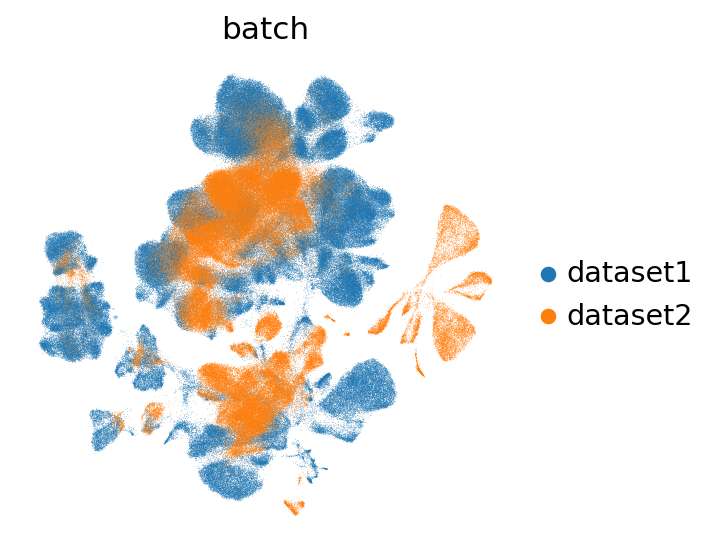

In [ ]:
sc.pl.umap(
    adata_ref,
    color=["batch"],
    frameon=False,
    ncols=1,
)
################################
################################
################################
################################
################################
################################
################################



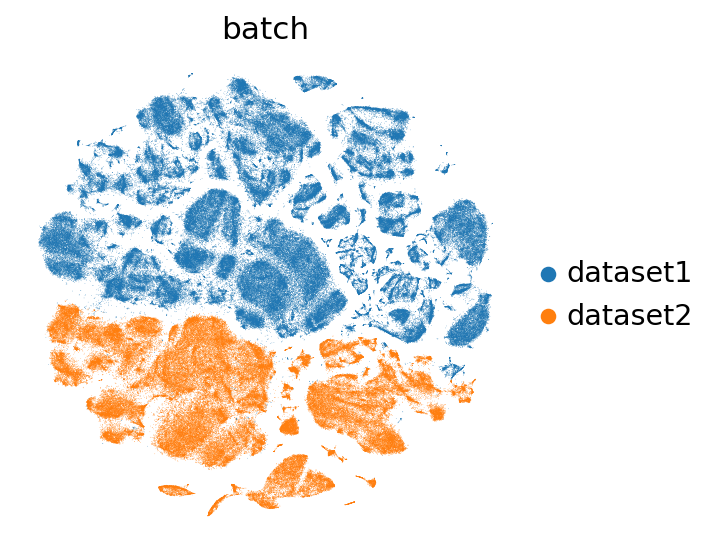

In [ ]:
sc.tl.tsne(adata_ref)

sc.pl.tsne(
    adata_ref,
    color=["batch"],
    frameon=False,
    ncols=1,
)
#####################################
#####################################
#####################################
####################################
####################################
###################################

In [ ]:
from sklearn.neighbors import NearestNeighbors
from scipy.stats import entropy
#####

def compute_batch_mixing_entropy(embedding, batch_labels, n_neighbors=50):


    nbrs = NearestNeighbors(n_neighbors=n_neighbors).fit(embedding)
    distances, indices = nbrs.kneighbors(embedding)

    entropies = []

    for i in range(len(indices)):

        neighbor_batches = batch_labels[indices[i]]

        unique, counts = np.unique(neighbor_batches, return_counts=True)
        probs = counts / len(neighbor_batches)

        entropies.append(entropy(probs))

    average_entropy = np.mean(entropies)
    print(average_entropy)
    return average_entropy

In [ ]:
compute_batch_mixing_entropy(adata_query.obsm["X_scVI"], adata_query.obs["batch"])

<ipython-input-41-8f5891b9adf9>:15: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  neighbor_batches = batch_labels[indices[i]]


0.18743190719222333


0.18743190719222333